# Task 1: Implementing SGA

## Introduction

This task covers the implementation of a Simple Genetic Algorithm (SGA) from the ground up. The algorithm, in its simplest form, can described as follows.

```pseudocode
Initialize population P of size N.
For G Generations: 
    Evaluate fitness of each individual in P
    Selects parents from P
    Apply one-point crossover on parents to create offspring
    Apply mutation on each offspring created
    Evaluate fitness of offspring
    Select the best individuals from current population and offspring
    Form new population P from the selected survivors
Return the best individuals
```

Both the contents of this report and the algorithm are divided by the individual functions implemented to perform key functionalities of the SGA. Each function is accompanied with a **subtask**, where the function is tested with some specified input, and its results are discussed.

### Input Space

Individuals of a population are analogs of a genetic representation, and fall into two categories: 

- **Phenotype:** Integer values
- **Genotype:** 6-bit binary strings.

Integer values are encoded as 6-bit binary strings (represented as a list) e.g., [0, 1, 0, 0, 1, 0] is 17. With 6 bits for each string, the values range from a minimum 0 to a maximum of 63. 

Populations are then represented by a list of list, e.g., [[0, 1, 0, 0, 0, 1], [1, 0, 0, 1, 1, 0], [0, 0, 1, 0, 0, 1]] is equivalent to [17, 38, 9].

## Starting Point

To ensure reproducability for multiple, different runs of the algorithm, we use a fixed seed that the `random` and `np.random` modules pull from. 
- **Seed:** 22040 (last five digits of the smallest student number in the group)    

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)


## Implementation

Below is the implementation of inidvidual functions- and the algorithm in its entirity. 

### Individual Functions

#### **Conversion Functions**

Used to convert the input space from **Genotype** to **Phenotype** and vice-versa, 

In [2]:
def geno_to_pheno(individuals):
    """Returns a list of the integer values corresponding to their the 6-bit binary value."""
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    """Returns a 6-bit binary string encoded as a list of integers."""
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

##### Helper Function

This small function is used to provide a clean, readable output formatting for the **Genotype** (binary string).

In [3]:
def geno_to_str( geno: list[list[int]] ):
    return "".join(map(str, geno))

#### **Initialization Function: (Inputs: Population Size; Output: Individuals)** 

This function creates individuals for a population of size `pop_size`, each having 6-bit genes chosen by random. It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]].

In [4]:
def initialization_population( pop_size: int, num_bits: int=6  ) -> list[list[int]]:
    """This function creates individuals for a population of size pop_size, each having 6-bit genes chosen by random. 
    It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]]. """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist()) # individual (6-bit binary string)
    return population

##### **Initalization Subtask** 

Tests the `initialization_population` function by having it generates 4 individuals. It outputs each one in order, and their type.

In [5]:
def initialize_population_subtask():
    individuals_geno = initialization_population(4)

    print("\033[1mIndividuals Generated (Genotype)\033[0m")
    print("-" * 32)
    for num, individual in enumerate(individuals_geno):
        print(f"Individual {num + 1}: {geno_to_str(individual)}")

initialize_population_subtask()

Individuals Generated (Genotype)
--------------------------------
Individual 1: 100100
Individual 2: 101001
Individual 3: 111111
Individual 4: 111000


#### **Fitness Function: (Inputs: Individuals; Output: Fitness values)**

This function takes a list of individuals as input, converts them to their integer value, and evaluates each individuals fitness value. It returns list of fitness values.  

The fitness evaluation equation is given as follows.

$$
y =
\begin{cases}
    x − 64, & \text{ if } x \ge 32 \\
    x, & \text{ if } x < 32
\end{cases}
\\
$$

$$
\begin{aligned}
    \text{fitness} &= − 0.00008333y^6 − 0.001y^5 + 0.09375y^4 \\
                   & \quad + 1.16667y3 − 19.53125y2 − 234.375y + 8350
\end{aligned}
$$

In [6]:
def fitness( individuals: list[list[int]] ) -> list[float]:
    """This function takes a list of individuals as input, converts them to their integer value, 
    and evaluates each individuals fitness value. Returns list of fitness values. """
    coeffs_exps_pairs = [
        (-0.00008333, 6),
        (-0.001, 5),
        (0.09375, 4),
        (1.16667, 3),
        (-19.53125, 2),
        (-234.375, 1),
        (8350, 0)
    ]

    def evaluate( value: float ) -> float:
        y_val = value - 64 if value >= 32 else value
        return sum(
                coeff * y_val**exp
                for coeff, exp in coeffs_exps_pairs
        )

    return [evaluate(value) for value in geno_to_pheno(individuals)]

##### **Fitness Subtask**

This subtask is compromised of two objectives:

1. Check for the individual = [[0, 1, 0, 1, 0, 1]] that their fitness value is approximately **12620.97**. 
2. Plot the fitness landscape (x-axis: integer values; y-axis: fitness) for all possible integer values.

Individual (Geno)  | Expected Fitness | Actual Fitness 
-------------------|------------------|---------------
010101             | 12_620.97        | 12_620.976507

- Fitness value IS within range: [12_620,12_621]

Plotting distribution of fitness values for all possible phenotype values (0 - 63):


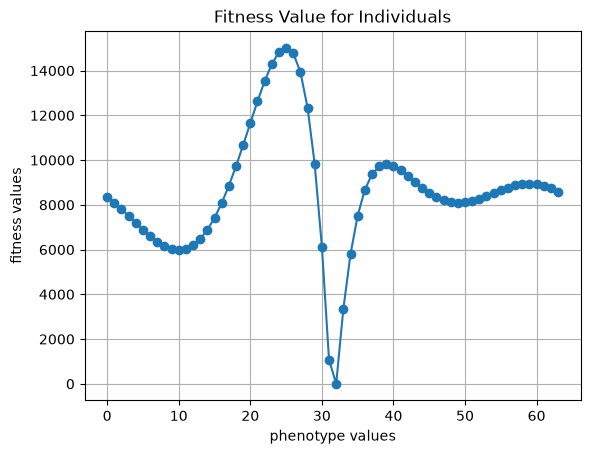

x-values corresponding to minimum/maximum fitness:

x-value | Fitness Value
--------|--------------
32      | 4.0832461
25      | 15024.0429688


In [7]:
def fitness_subtask( individual: list[list[int]], samples: int ):
    expected = 12_620.97
    fitness_value = fitness(individual)

    print(f"\033[1mIndividual (Geno)\033[0m{"":<1} | \033[1mExpected Fitness\033[0m | \033[1mActual Fitness\033[0m ")
    print("-" * 19 + "|" + "-" * 18 + "|" + "-" * 15)
    print(f"{geno_to_str(individual[0])}{"":<12} | {expected:_} {"":<6} | {fitness_value[0]:_.6f}\n")

    if 12_620 <= fitness_value[0] <= 12_621:
        print(f"- Fitness value IS within range: [{12_620:_},{12_621:_}]\n")
    else:
        print(f"- Fitness value NOT within range: [{12_620:_},{12_621:_}]\n")

    print("Plotting distribution of fitness values for all possible phenotype values (0 - 63):")
    x_vals = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_vals))

    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)

    plt.plot(x_vals, fitness_values, marker='o')
    plt.title("Fitness Value for Individuals")
    plt.xlabel("phenotype values")
    plt.ylabel("fitness values")
    plt.grid(True)
    plt.show()

    print("x-values corresponding to minimum/maximum fitness:\n")
    print("\033[1mx-value\033[0m | \033[1mFitness Value\033[0m")
    print("-" * 8 + "|" + "-" * 14)    
    print(f"{x_min:<7} | {fitness_values[x_min]:.7f}")
    print(f"{x_max:<7} | {fitness_values[x_max]:.7f}")

fitness_subtask([[0, 1, 0, 1, 0, 1]], 64)

From the output we can see that the x-values that correspond to the minimum and maximum fitness values are:

- **Minimum:** 32 : 4.0832461
- **Maximum:** 25 : 15024.0429688

##### Generate Trial Set

This function is useful for later subtasks as it quickly generates, and returns a uniform population of size `samples`, their fitness values, and the x values that correspond to the minimum and maximum fitness across that range.

**Subtasks that employ it:**

- Parent Selection Subtask
- Survivor Selection Subtask

In [8]:

def generate_population_and_fitness_values( samples: int=64 ) -> tuple[list[int], list[float], float, float]:
    """Helper function to generate N samples and their fitness values. 
    Returns the individuals, their fitness values, and the x-values that correspond to the min/max fitness."""
    x_values = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_values))
    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)
    return x_values, fitness_values, x_min, x_max


##### **Parent Selection Function: (Inputs: Individuals, Fitness values; Output: Parents (in random order))**

Perform fitness-proportional selection such that more fit parents have a higher probability to be selected.Returns a list of the selected individuals in random order.

In [9]:
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional selection such that more fit parents have a higher probability to be selected. 
    Returns a list of the selected individuals in random order """
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

##### **Parent Selection Subtask**

This subtask tests the `parent_selection` function by providing it a set of four individuals to perform on. The individuals chosen are those who correspond to: 

1. minimum fitness, 
2. moderate fitness,
3. moderate fitness,
4. and maximum fitness.
    
These individuals were deliberately chosen to test the fitness-proportional selection criteria, that is, we expect that the individual with the highest fitness value is selected the most and we want to verify that. 

This subtask performs two distinct runs: 

- **First run** performs a "single-iteration" of selection process, but since the selection is influenced by a randomized factor and that we are looking for a desirable run to highlight the enforcement of the selection criteria, we do allow for multiple iterations. These additional iterations are done until the highest fit individual is selected the most out of the input set. To offset this "cheating" we include the number of additional iterations required to achieve this result and perform the run 3 times to highlight the low number of additional iterations.

- **Second run** performs 10,000, indisciminatory iterations of the selection process and outputs the rate (in percentages) each individual was selected. By indiscriminatory we mean that, unlike the previous run, no additional runs are done to ensure the highest fit individual is chosen the most. The reason for including this additional run is to show that, for enough iterations and without any bias, the random factor becomes trivial and the highest-fit individual is always chosen at the highest rate.     


In [10]:
def parent_selection_iterations( x_values: list[int], fit_vals: list[float], num_iter: int=1,  
                                require_max_most: bool=False ) -> tuple[dict, list[list[int]], int]:
    """Runs parent selection num_iter times and returns (selection counts, last parents, attempts).
    If require_max_most is set, runs where the fittest individual isn't selected the most are rejected."""
    x_vals_geno = pheno_to_geno(x_values)
    counts = { val : 0 for val in x_values }
    x_max = x_values[np.argmax(fit_vals)]
    n, attempts = num_iter, 0

    while n > 0:
        attempts += 1
        parents = parent_selection(x_vals_geno, fit_vals)
        run_counts = {val: 0 for val in x_values}
        for p in geno_to_pheno(parents):
            run_counts[p] += 1

        # For single-iteration we employ discriminatory parent selecting,
        # i.e. selecting the run where x_max is counted the most.
        if require_max_most and run_counts[x_max] < max(run_counts.values()):
            continue  # reject this run, nothing added to totals

        for val, c in run_counts.items():
            counts[val] += c
        n -= 1

    return counts, parents, attempts

def parent_selection_subtask():
    # Selects test subjects (x values) based on their fitness level (min, medium, medium, max)
    _, fitness_vals, x_min, x_max = generate_population_and_fitness_values(samples=64)
    
    mid_fit = (fitness_vals[x_min] + fitness_vals[x_max]) / 2
    closest = np.argsort(np.abs(np.array(fitness_vals) - mid_fit))
    x_mod1, x_mod2 = closest[0], closest[1]

    x_values = [x_min, x_mod1, x_mod2, x_max]
    fit_vals = [
        fitness_vals[x_min],
        fitness_vals[x_mod1],
        fitness_vals[x_mod2],
        fitness_vals[x_max]
    ]

    singles = [parent_selection_iterations(x_values, fit_vals, require_max_most=True) for _ in range(3)]
    num_iter = 10_000
    totals, _, _ = parent_selection_iterations(x_values, fit_vals, num_iter)

    print(f"{'\033[1mGenotype\033[0m':<20}{'\033[1mx\033[0m':>6}{'\033[1mFitness\033[0m':>21}{'\033[1mRun 1\033[0m':>15}" +
          f"{'\033[1mRun 2\033[0m':>15}{'\033[1mRun 3\033[0m':>15}{'\033[1mRate (10k)\033[0m':>20}")
    print("-" * 60)
    for g, x, f in zip(pheno_to_geno(x_values), x_values, fit_vals):
        runs = "".join(f"{c[x]:>6}x" for c, _, _ in singles)
        print(f"{geno_to_str(g):<9}{x:>4}{f:>13.4f}{runs}{totals[x] / (num_iter * len(x_values)):>12.4%}")

    print()
    for i, (_, parents, attempts) in enumerate(singles, 1):
        label = f"Run {i} parents ({attempts} attempt{'s' * (attempts > 1)}):"
        print(f"{label:<28}{', '.join(geno_to_str(p) for p in parents)}")


parent_selection_subtask()

Genotype    x      Fitness  Run 1  Run 2  Run 3  Rate (10k)
------------------------------------------------------------
100000     32       4.0832     0x     0x     0x     0.0200%
000011      3    7509.8838     1x     2x     1x    25.3250%
100011     35    7519.2945     0x     0x     1x    25.1275%
011001     25   15024.0430     3x     2x     2x    49.5275%

Run 1 parents (1 attempt):  011001, 011001, 000011, 011001
Run 2 parents (1 attempt):  000011, 011001, 011001, 000011
Run 3 parents (2 attempts): 100011, 011001, 000011, 011001


As we can see from the output, the first run the individual [0, 1, 1, 0, 0, 1] is chosen nearly **2x** as often than the runner-up ([0, 0, 0, 0, 1, 1]), with an average re-attempt rate of **~1.333...** to achieve that result.

Looking at the second run, we see that despite exluding any discrimanatory practices the highest fit individual is still selected the most (by far) out of the 4, with a selection rate of **49.5275%** compared the runner up who's selection rate comes to **25.3250%** (nearly 2x difference).

#### **Recombination (Crossover) Function: (Inputs: Parents, Crossover Probability $P_C$; Outputs: Offspring (pre-Mutation))**

This function performs one-point crossover and generates for every pair of (e.g., parents 1 & 2, parents 3 & 4 etc.) offspring. If the crossover probability does not exceed some alpha value (random, uniform number $\in [0, 1]$), crossover is performed, and the point at which the crossover occurs is some random number $\in [1, 6]$. If the number of parents is odd, it simply copies the last parent to the end of the list.

In [11]:
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings

##### **Recombination (Crossover) Subtask**

In this subtask we initialize two parents (in this case [[0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 1, 1]]) and with a crossover probability of 85% we test out the function. Once crossover has been performed, we output the parents and the newly generated offsprings as well as the crossover point (if it occured). 

The reason for selecting these parents in particular is that they mirror one another, which creates a clear contrast between eachother that makes finding the cutoff point much easier.

In [12]:
def find_cutoff(parent, offspring):
    """Finds and returns the index where parent bit and offspring bit differ. """
    for i, (p, o) in enumerate(zip(parent, offspring)):
        if p != o:
            return i
    return None  # identical: no crossover happened


def recombination_subtask():
    parents = [[0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 1, 1]] # 28 and 35
    offsprings = one_point_crossover( parents, 0.85 )

    parent_items = [geno_to_str(parent) for parent in parents]
    offspring_items = [geno_to_str(offspring) for offspring in offsprings]

    label_width = 11
    column_width = max(map(len, parent_items + offspring_items)) + 2

    print("\033[1mRecombination (probability 0.85)\033[0m")
    print("-" * 32)

    print(f"{'Parents:':<{label_width}}" +
        "".join(f"{item:<{column_width}}" for item in parent_items))

    print(f"{'Offspring:':<{label_width}}" +
        "".join(f"{item:<{column_width}}" for item in offspring_items))

    cutoff = find_cutoff(parents[0], offsprings[0])
    print(f"{'Cutoff:':<{label_width}}" + f"{cutoff if cutoff else "No crossover occurred"}")

recombination_subtask()


Recombination (probability 0.85)
--------------------------------
Parents:   011100  100011  
Offspring: 011100  100011  
Cutoff:    No crossover occurred


#### **Mutation Function: (Inputs: Individuals, Mutation Probability $P_M$; Outputs: Offspring (mutated))** 

The function `mutation` performs, for each individual, mutation (bitflip) for each gene (bit) with a mutation probability of $P_M$. Similarly to crossover, we compare the probability to an alpha value (random uniform number $\in [0, 1]$) to decide whether or not to perform the mutation. If it does not exceed it, the value for the gene is flipped (e.g., from 0 to 1 or vice versa).

In [13]:
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated

##### **Mutation Function Subtask**

Here we use the individual [0, 1, 0, 1, 1, 0] as input for the `mutation` function - once with the probability of 0.2 and once with a probability of 0.9. For each probability, we calculate an *estimated* number of mutations that should occur. For the higher higher probabilty case we obviously expect a higher numbeer of mutations to occur, and a lower number of the other case.

In [14]:
def mutation_subtask():
    individual = [0, 1, 0, 1, 1, 0] # 22
    
    mut_prob1, mut_prob2   = 0.2, 0.9
    expected_1, expected_2 = mut_prob1 * 6, mut_prob2 * 6
    mutated1, mutated2     = mutation( [individual], mut_prob1 ), mutation( [individual], mut_prob2 )

    count_flips = lambda original, mutated: sum(
        a != b for a, b in zip(original, mutated)
    )

    num_flip1, num_flip2 = count_flips(individual, mutated1[0]), count_flips(individual, mutated2[0])

    print(f"\033[1mIndividual Pre-Mutation: {geno_to_str(individual)}\033[0m\n") 

    print(f"\033[1mPost-Mutation\033[0m | \033[1mProb.\033[0m | \033[1mExpected Flips\033[0m | \033[1mActual Flips\033[0m")
    print("-" * 14 + "|" + "-" * 7 + "|" + "-" * 16 + "|" + "-" * 14)
    print(f"{geno_to_str(mutated1[0])} {"":<7}| {str(mut_prob1):<5} | {expected_1:.4f}{"":<8} | {num_flip1:.4f}")
    print(f"{geno_to_str(mutated2[0])} {"":<7}| {str(mut_prob2):<5} | {expected_2:.4f}{"":<8} | {num_flip2:.4f}")

mutation_subtask()

Individual Pre-Mutation: 010110

Post-Mutation | Prob. | Expected Flips | Actual Flips
--------------|-------|----------------|--------------
100110        | 0.2   | 1.2000         | 2.0000
101001        | 0.9   | 5.4000         | 6.0000


The resulting mutations for the individual correlates well with our estimated values. With only 6 bits as our baseline, the margin of error between the actual- estimated number of flips is trivial; as long as it's within the range of +1 or -1 bits flipped. 

#### **Survivor Selection Function: (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring; Outputs: (New) population)**

This function performs deterministic survivor selection (no randomness / stochasticity here) by selecting the survivors from among the population individuals and the offspring based purely on the highest fitness values. The resulting population size remains the same.

In [15]:
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]]        

##### **Survivor Selection Function Subtask**

To start, using `generate_population_and_fitness_values()`, we generate a new population of 64 individuals and their fitness values. Using the `x_min` and `x_max`, we provide the `survivor_selection` function the individual leading to the lowest fitness and the one leading to the highest fitness. 

Picking these two in particular gives the function a clear victor to select, making it easier to verify its intended behavior.   

In [16]:
def survivor_selection_subtask():
    _, fit_values, x_min, x_max = generate_population_and_fitness_values()
    individual = pheno_to_geno([x_min])
    offspring  = pheno_to_geno([x_max])
    fit_individual = [fit_values[x_min]]
    fit_offspring  = [fit_values[x_max]]

    combined = individual + offspring
    combined_fitness = fit_individual + fit_offspring

    print(f"\033[1mIndividual (Geno)\033[0m | \033[1mFitness Value\033[0m ")
    print("-" * 18 + "|" + "-" * 15)
    for ind, fit in zip(combined, combined_fitness):
        print(f"{geno_to_str(ind)}{"":<11} | {fit:.6f}")
    
    survivors = survivor_selection(individual, offspring, fit_individual, fit_offspring)
    print(f"\033[1m\nSurvivor:\033[0m {geno_to_str(survivors[0])}")

survivor_selection_subtask()

Individual (Geno) | Fitness Value 
------------------|---------------
100000            | 4.083246
011001            | 15024.042969

Survivor: 011001


### **Loop**

This is the complete version of the SGA that utilizes the implemented functions as described in the introduction. The function `simple_genetic_algorithm` (responsible for executing the algorithm) takes one argument `params`, a dictionary containing the hyper-paramaters for the SGA and are as follows.  

1. **`n_pop`:** Controls the population size.
2. **`n_iter`:** Termination criteria. Fixed number of algorithm iterations or generations to produce.
3. **`c_prob`:** Probability that crossover (recombination) occurs between parent chromosomes.
4. **`m_prob`:** Determines how frequently random changes occur in the offspring.
5. **`n_bits`:** Defines the number of bits in a single candidate solution.

With the exception of `n_pop` and `n_iter`, the other hyper-parametrs remain constant throughout the different runs.

On each iteration we record the average- and best fit that is later used for plotting the result of the SGA run.   

In [17]:
def simple_genetic_algorithm( params: dict[str, int | float ] ) -> tuple[list[float], list[float]]:
    population = initialization_population( params["n_pop"] )
    avg_fit_data, best_fit_data = [], []

    for _ in range( params["n_iter"] ):
        fitness_values = fitness( population )
        
        avg_fit_data.append( np.mean(fitness_values) )
        best_fit_data.append( np.max(fitness_values) )
                
        parents = parent_selection(population, fitness_values)
        offspring = one_point_crossover( parents, params["c_prob"] )
        offspring = mutation(offspring, params["m_prob"])
        survivors = survivor_selection(population, offspring, fitness_values, fitness(offspring))    

        population = survivors

    return avg_fit_data, best_fit_data

##### **SGA Subtask** 

The `sga_trial_and_results` function performs a single trial of $N$ runs of the SGA algorithm, where each run is done with different combinations of `n_pop` and `n_iter` hyper-parameters. The resulting  history of the average- and best fitness values are then plotted on a 2D graph (x-axis: generations, y-axis: fitness values). 

The plot converys clearly the following: 

- How fast the average fitness value of the population increased per generation, 
- At what genertion does the fitness value reach its maximum and then plateau.
- When the average- and best fitness values converge (if they do).  

The `find_convergance` function flags the first time average meets best, so with tiny populations it can mark a false convergence. Small populations lose diversity fast and get stuck, while bigger populations start with a better chance of already containing a high-fitness individual.

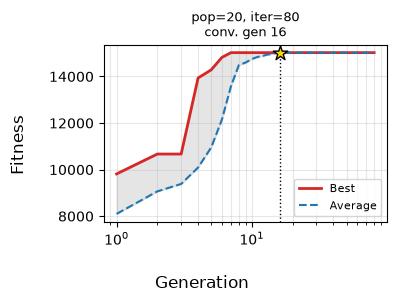

 Population  Iterations  Final avg.  Final best  Conv. gen
         20          80    15,024.0    15,024.0         16


In [18]:
import math    
import itertools
import pandas as pd

def display_dataframe(df: pd.DataFrame):
    cols = {"pop_size": "Population", "n_iter": "Iterations",
            "final_avg": "Final avg.", "final_best": "Final best", "conv_gen": "Conv. gen"}

    lines = (df[list(cols)].rename(columns=cols)
               .to_string(index=False, float_format="{:,.1f}".format, na_rep="-")
               .splitlines())

    print(f"\033[1m{lines[0]}\033[0m")
    print("\n".join(lines[1:]))


def find_convergence(avg, best, tolerance=0.001):
    """First generation (1-based) where the average is within tol (0.1%) of the best."""
    
    for gen, (a, b) in enumerate(zip(avg, best), start=1):
        if (b - a) / abs(b) <= tolerance:
            return gen
    return None

def sga_trial_and_results( n_pop: int | list[int], n_iter: int | list[int], tolerance: float=0.001, paired: bool=False ) -> pd.DataFrame:
    """Runs the SGA for every (pop_size, n_iter) combination. """

    pop_sizes   = n_pop  if isinstance(n_pop,  (list, tuple)) else [n_pop]
    iter_counts = n_iter if isinstance(n_iter, (list, tuple)) else [n_iter]

    if paired:
        combos = list(zip(pop_sizes, iter_counts, strict=True))
    else:
        combos = list(itertools.product(pop_sizes, iter_counts))

    # Most square grid that fits all plots: 4 -> 2x2, 6 -> 2x3, 9 -> 3x3, 16 -> 4x4
    n_plots = len(combos)
    n_cols  = math.ceil(math.sqrt(n_plots))
    n_rows  = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                             sharey=True, squeeze=False)
    axes = axes.flatten()   # 1D, so we can just walk through them in order
    
    results = []

    for ax, (n_pop, n_iter) in zip(axes, combos):

        # Hyperparameters: 
        # - Only n_pop and n_iter are adjustable.
        # - Others remain constant.
        sga_hparams = { 
            "n_pop": n_pop,
            "n_iter": n_iter,
            "c_prob": 0.85,
            "m_prob": 1/6, 
            "n_bits": 6,
        }

        avg_fit_data, best_fit_data = simple_genetic_algorithm( sga_hparams )
        gens = np.arange(1, n_iter + 1)          # start at 1: log(0) is undefined

        ax.plot(gens, best_fit_data, color="tab:red",  lw=2,            label="Best")
        ax.plot(gens, avg_fit_data,  color="tab:blue", lw=1.5, ls="--", label="Average")
        ax.fill_between(gens, avg_fit_data, best_fit_data, color="tab:gray", alpha=0.2)

        gen = find_convergence(avg_fit_data, best_fit_data, tolerance)
        if gen:
            ax.axvline(gen, color="black", ls=":", lw=1)
            ax.scatter(gen, best_fit_data[gen-1], marker="*", s=120, color="gold", edgecolor="black", zorder=5)

        if n_iter >= 20:              # log scale only helps for longer runs
            ax.set_xscale("log")
        ax.set_title(f"pop={n_pop}, iter={n_iter}\n" + (f"conv. gen {gen}" if gen else "not converged"),
                     fontsize=9)
        ax.grid(True, which="both", alpha=0.3)

        results.append({"pop_size": n_pop, "n_iter": n_iter,
                        "final_avg": avg_fit_data[-1], "final_best": best_fit_data[-1], "conv_gen": gen})

    for ax in axes[n_plots:]:
        ax.set_visible(False)

    axes[0].legend(fontsize=8)
    fig.supxlabel("Generation")
    fig.supylabel("Fitness")
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(results)

display_dataframe( sga_trial_and_results( 20, 80 ) )

In this instance we conducted a single-run SGA trial with a population size of 20 and 80 as the number of generations. We see that the best and average fitness is non-decreasing, and this is because survivor selection is deterministic $(\mu + \lambda)$ truncation, so the top individuals always survive.

A single run doesn't tell us much regarding the relationship between the population size and number of genertions, which is why we will later on test it with more varied parameter combinations. 

#### **Testing with varied parameters**

We perform 4 distinct trials, with each trial conducting 4 runs.

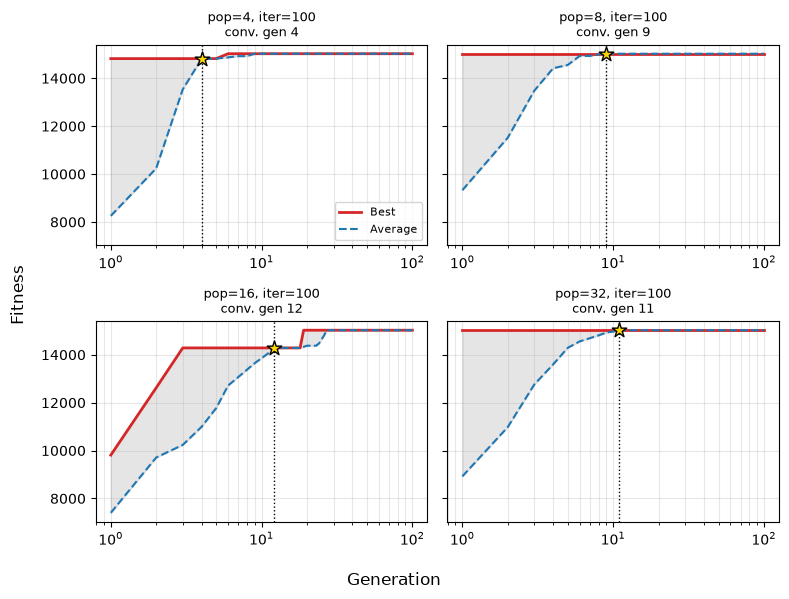

 Population  Iterations  Final avg.  Final best  Conv. gen
          4         100    15,024.0    15,024.0          4
          8         100    15,024.0    15,024.0          9
         16         100    15,024.0    15,024.0         12
         32         100    15,024.0    15,024.0         11


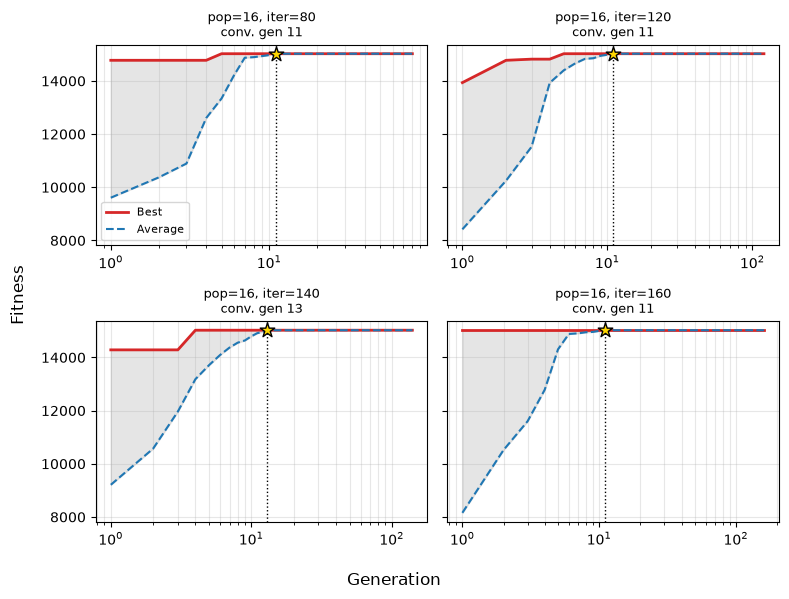

 Population  Iterations  Final avg.  Final best  Conv. gen
         16          80    15,024.0    15,024.0         11
         16         120    15,024.0    15,024.0         11
         16         140    15,024.0    15,024.0         13
         16         160    15,024.0    15,024.0         11


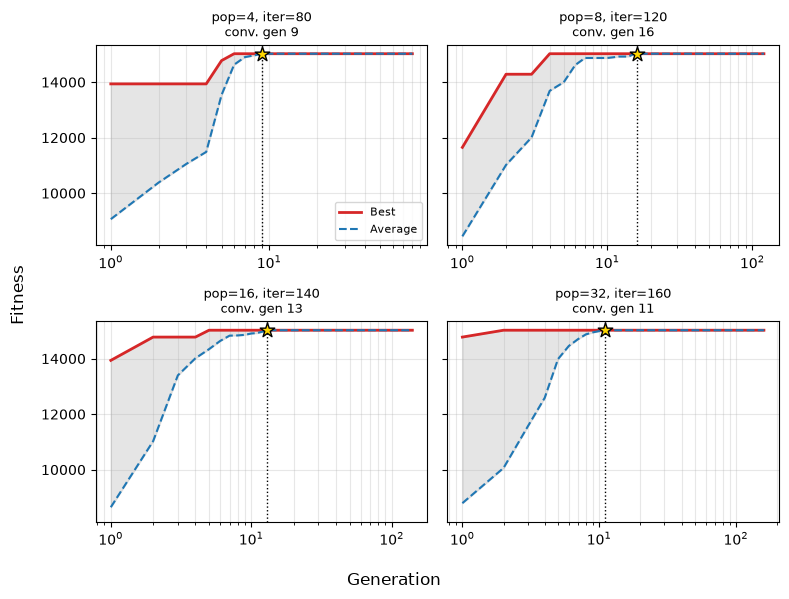

 Population  Iterations  Final avg.  Final best  Conv. gen
          4          80    15,024.0    15,024.0          9
          8         120    15,024.0    15,024.0         16
         16         140    15,024.0    15,024.0         13
         32         160    15,024.0    15,024.0         11


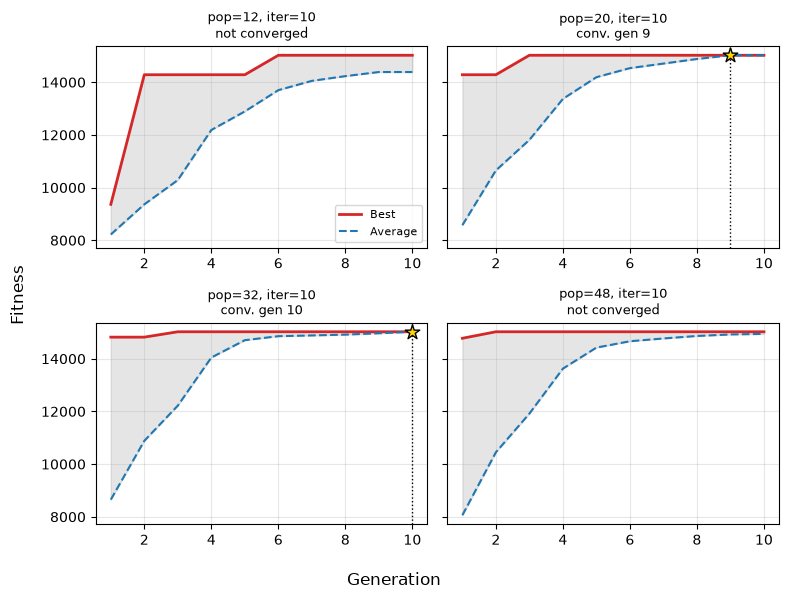

 Population  Iterations  Final avg.  Final best  Conv. gen
         12          10    14,387.7    15,024.0          -
         20          10    15,024.0    15,024.0        9.0
         32          10    15,024.0    15,024.0       10.0
         48          10    14,943.2    15,024.0          -


In [19]:


# Trial 1: Ppopulation size doubles and fixed number of iterations
t1_n_pop, t1_n_iter = [4, 8, 16, 32], 100

# Trial 2: Fixed population size and number of iterations increases
t2_n_pop, t2_n_iter  = 16, [80, 120, 140, 160]

# Trial 3: Both population size and number of iterations increase
t3_n_pop, t3_n_iter =  [4, 8, 16, 32], [80, 120, 140, 160]

# Trial 4: Number of iterations < population size
t4_n_pop,  t4_n_iter = [12, 20, 32, 48], 10

trials = [ (t1_n_pop, t1_n_iter),
            (t2_n_pop, t2_n_iter),
            (t3_n_pop, t3_n_iter),
            (t4_n_pop,  t4_n_iter)
        ]

for n_pop, n_iter in trials:
    if isinstance(n_pop, int) or isinstance(n_iter, int):
        df: pd.DataFrame = sga_trial_and_results( n_pop, n_iter )
    else:
        df: pd.DataFrame = sga_trial_and_results( n_pop, n_iter, paired=True )
    display_dataframe( df )

After having ran the algorithm numerous times with the different parameters, we can see some very interesting pattterns emerge. The fastests convergence, at generation 5, occured during the third run of the second trial, where we set the population size and number of generations to 16 and 140. 

The second fastests occured during the thrid run of the fourth trial, where convergence occured at generation 6. In this trial, we set out to inspect the impact of having the number of generation be less than the population size, and in most runs of the trial convergence either occured at the tail-end of the algorithm or not at all. So the first run might likely just be a outlier caused by the randomizing factor. These results seem to suggest that for a successful application of the algorithm the disparity between the population size and number of generations needs to be quite high. 

The most consistent trials came out to be the first- and second one. Analyzing the two, we see that the fastests convergence for the two occurred duirng the first- and third run respectively. For the former, the ratio between population size and number of generations comes out to $1:25$, while for the latter the ratio comes out to $1:8.75$. The difference in ratio between the two runs, despite the similar results, is quite interesting. While the population size increased $4\times$, the number of generations only increased by $40\%$. We therefore conduct further trials to see if there is some pattern there.  

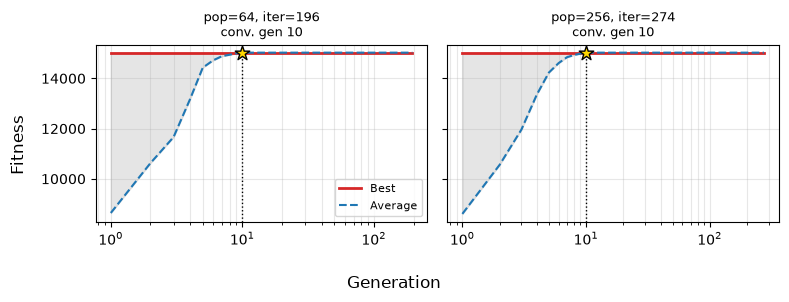

 Population  Iterations  Final avg.  Final best  Conv. gen
         64         196    15,024.0    15,024.0         10
        256         274    15,024.0    15,024.0         10


In [20]:
# Trial 5: Population size increases 4x and number of iterations increases by 40%
t5_n_pop, t5_n_iter = [64, 256], [196, 274]

display_dataframe( sga_trial_and_results( t5_n_pop, t5_n_iter, paired=True) )

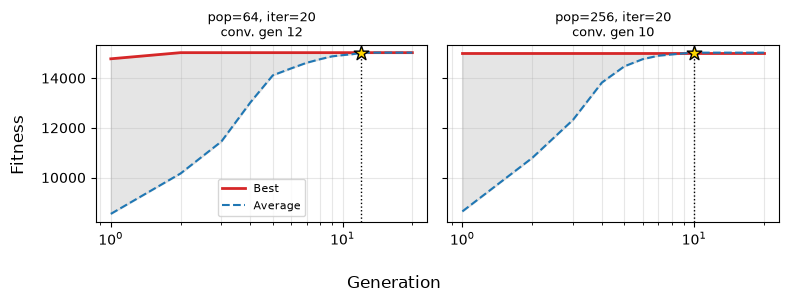

 Population  Iterations  Final avg.  Final best  Conv. gen
         64          20    15,024.0    15,024.0         12
        256          20    15,024.0    15,024.0         10


In [21]:
# Trial 6: Population size increases 4x from 1 and second, and number of iterations is fixed
t6_n_pop, t6_n_iter = [64, 256], 20

display_dataframe( sga_trial_and_results( t6_n_pop, t6_n_iter ) )

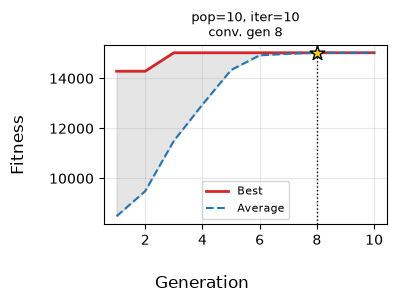

 Population  Iterations  Final avg.  Final best  Conv. gen
         10          10    15,024.0    15,024.0          8


In [22]:
# Trial 7: Population size and and number of iterations is fixed
t7_n_pop, t7_n_iter = 10, 10

display_dataframe( sga_trial_and_results( t7_n_pop, t7_n_iter ) )

Looking at the result of the trials, we see that the rate at which convergence occurs doesn't correlate to this supposed pattern, and might more have to do with the raw population size. This makes sense, since havinga lower population size means the average fitness would rise at a much faster rate than a larger population. From these results, we can see that the number of generations doesn't directly impact the rate of growth for the average fitness values.